In [1]:
import os
import glob
import time
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving bbc-text.csv to bbc-text.csv
Uploaded files: ['bbc-text.csv']


In [3]:
# Extract any uploaded ZIP files
for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall("/content/bbc_dataset")

# Find CSV files
csv_files = glob.glob("/content/bbc_dataset/**/*.csv",
                      recursive=True)
csv_files += glob.glob("/content/*.csv")

# Remove duplicate file paths
csv_files = list(dict.fromkeys(csv_files))

print("CSV files found:")
for i, filename in enumerate(csv_files):
    print(i, filename)

CSV files found:
0 /content/bbc-text.csv


In [4]:
data_path = next(
    (f for f in csv_files
     if os.path.basename(f).lower() == "bbc-text.csv"),
    csv_files[0] if csv_files else None
)

if data_path is None:
    raise FileNotFoundError(
        "No CSV found. Upload the Kaggle ZIP or CSV file."
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (2225, 2)


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


Columns: ['category', 'text']


In [5]:
print("Number of documents:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumn information:")
print(df.info())

display(df.head(3))

Number of documents: 2225
Number of columns: 2

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   text      2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB
None


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...


In [6]:
# Find the text and label columns automatically
column_map = {
    str(col).strip().lower(): col for col in df.columns
}

text_candidates = ["text", "article", "content", "news"]
label_candidates = ["category", "label", "class", "topic"]

text_col = next(
    (column_map[c] for c in text_candidates
     if c in column_map), None
)
label_col = next(
    (column_map[c] for c in label_candidates
     if c in column_map), None
)

if text_col is None or label_col is None:
    raise ValueError(
        f"Could not identify text and label columns. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df[[text_col, label_col]].copy()
df.columns = ["text", "category"]

# Basic data cleaning
df = df.dropna(subset=["text", "category"])
df["text"] = df["text"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()
df = df[(df["text"] != "") & (df["category"] != "")]
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Documents after cleaning:", len(df))
print("\nClass labels:")
print(sorted(df["category"].unique()))

Documents after cleaning: 2126

Class labels:
['business', 'entertainment', 'politics', 'sport', 'tech']


In [7]:
class_counts = df["category"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Documents": class_counts,
    "Percentage": (
        class_counts / len(df) * 100
    ).round(2)
})

display(distribution)

print("Largest class:", class_counts.max())
print("Smallest class:", class_counts.min())
print(
    "Largest-to-smallest class ratio:",
    round(class_counts.max() / class_counts.min(), 2)
)

,Documents,Percentage
category,,
business,503,23.66
entertainment,369,17.36
politics,403,18.96
sport,504,23.71
tech,347,16.32


Largest class: 504
Smallest class: 347
Largest-to-smallest class ratio: 1.45


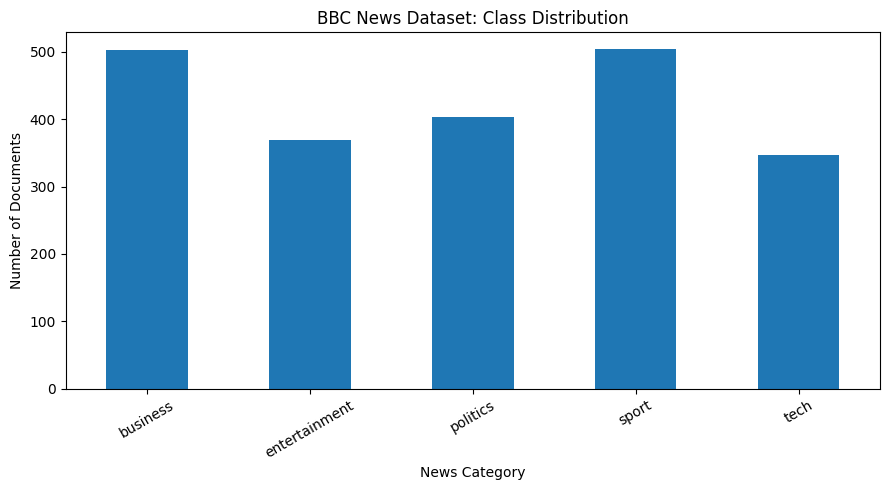

In [8]:
plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("BBC News Dataset: Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
X = df["text"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training documents: 1700
Testing documents: 426

Training class distribution:
category
business         402
entertainment    295
politics         322
sport            403
tech             278
Name: count, dtype: int64

Testing class distribution:
category
business         101
entertainment     74
politics          81
sport            101
tech              69
Name: count, dtype: int64


In [10]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000,
    min_df=2,
    ngram_range=(1, 1),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))
print("Training matrix nonzero values:", X_train_tfidf.nnz)

Training feature matrix: (1700, 15258)
Testing feature matrix: (426, 15258)
Number of TF-IDF features: 15258
Training matrix nonzero values: 236294


In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=300
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=0.1
    )
}

results = []
predictions = {}
training_times = {}
testing_times = {}

for name, model in models.items():
    # Measure training time
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    training_times[name] = time.perf_counter() - start

    # Measure prediction time
    start = time.perf_counter()
    y_pred = model.predict(X_test_tfidf)
    testing_times[name] = time.perf_counter() - start

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ),
        "Recall (weighted)": recall_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ),
        "F1-score (weighted)": f1_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test, y_pred, average="macro",
            zero_division=0
        ),
        "Training time (s)": training_times[name],
        "Testing time (s)": testing_times[name]
    })

results_df = pd.DataFrame(results)

print("All four models trained and evaluated.")
display(results_df.round(4))

All four models trained and evaluated.


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,Decision Tree,0.8310,0.8320,0.8310,0.8305,0.8253,0.9706,0.0014
1,KNN,0.9812,0.9813,0.9812,0.9812,0.9801,0.0028,0.1324
2,SVM,0.9765,0.9771,0.9765,0.9766,0.9770,0.0974,0.0016
3,Naive Bayes,0.9671,0.9674,0.9671,0.9671,0.9655,0.0078,0.0010


In [12]:
comparison = results_df.sort_values(
    "F1-score (weighted)",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

print(
    "Best model by weighted F1:",
    comparison.loc[0, "Model"]
)

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,KNN,0.9812,0.9813,0.9812,0.9812,0.9801,0.0028,0.1324
1,SVM,0.9765,0.9771,0.9765,0.9766,0.9770,0.0974,0.0016
2,Naive Bayes,0.9671,0.9674,0.9671,0.9671,0.9655,0.0078,0.0010
3,Decision Tree,0.8310,0.8320,0.8310,0.8305,0.8253,0.9706,0.0014


Best model by weighted F1: KNN


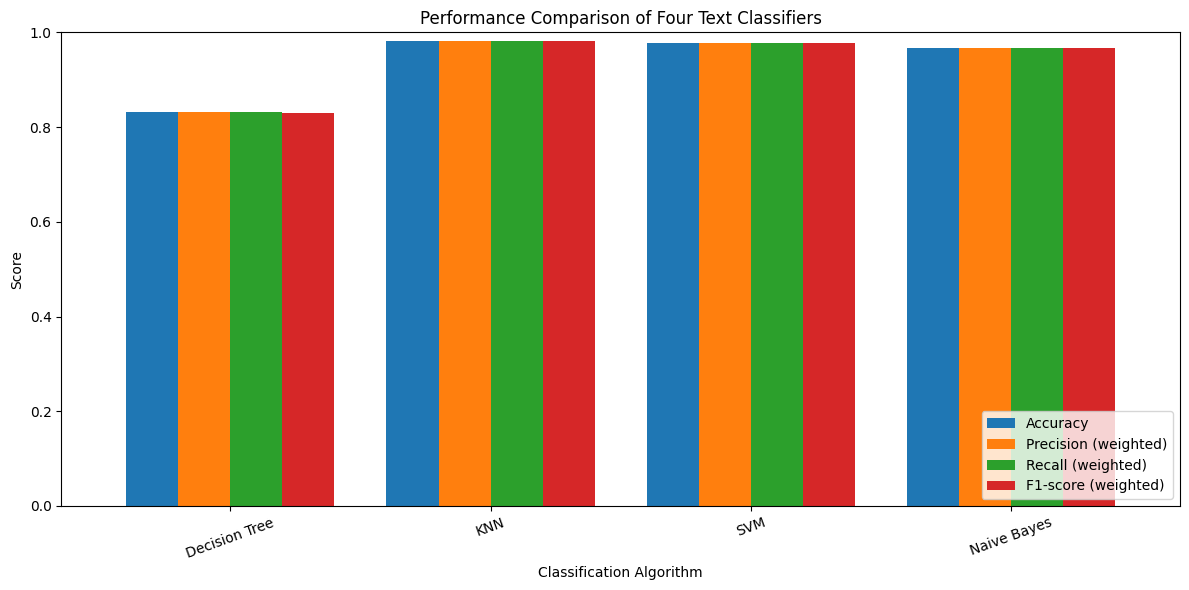

In [13]:
metric_cols = [
    "Accuracy",
    "Precision (weighted)",
    "Recall (weighted)",
    "F1-score (weighted)"
]

plot_df = results_df.set_index("Model")[metric_cols]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Performance Comparison of Four Text Classifiers")
ax.set_xlabel("Classification Algorithm")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

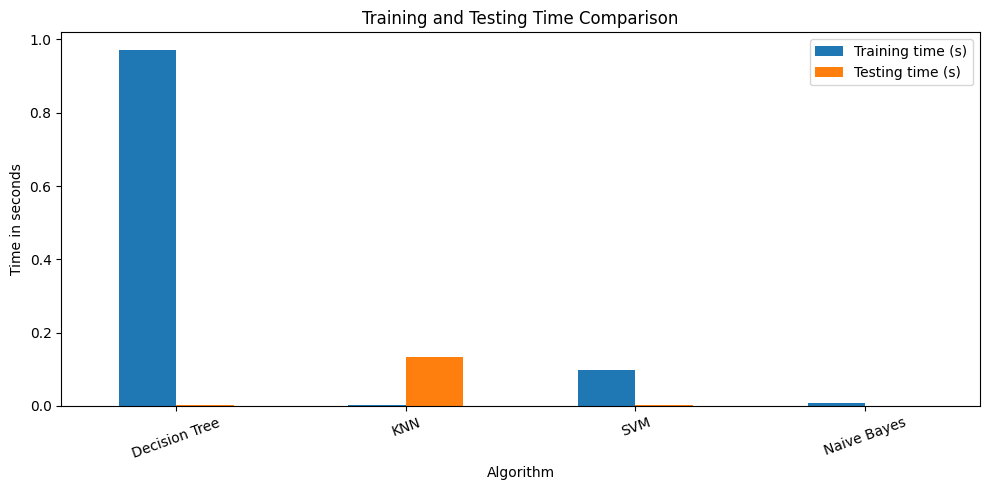

In [14]:
time_df = results_df.set_index("Model")[
    ["Training time (s)", "Testing time (s)"]
]

time_df.plot(kind="bar", figsize=(10, 5))
plt.title("Training and Testing Time Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Time in seconds")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

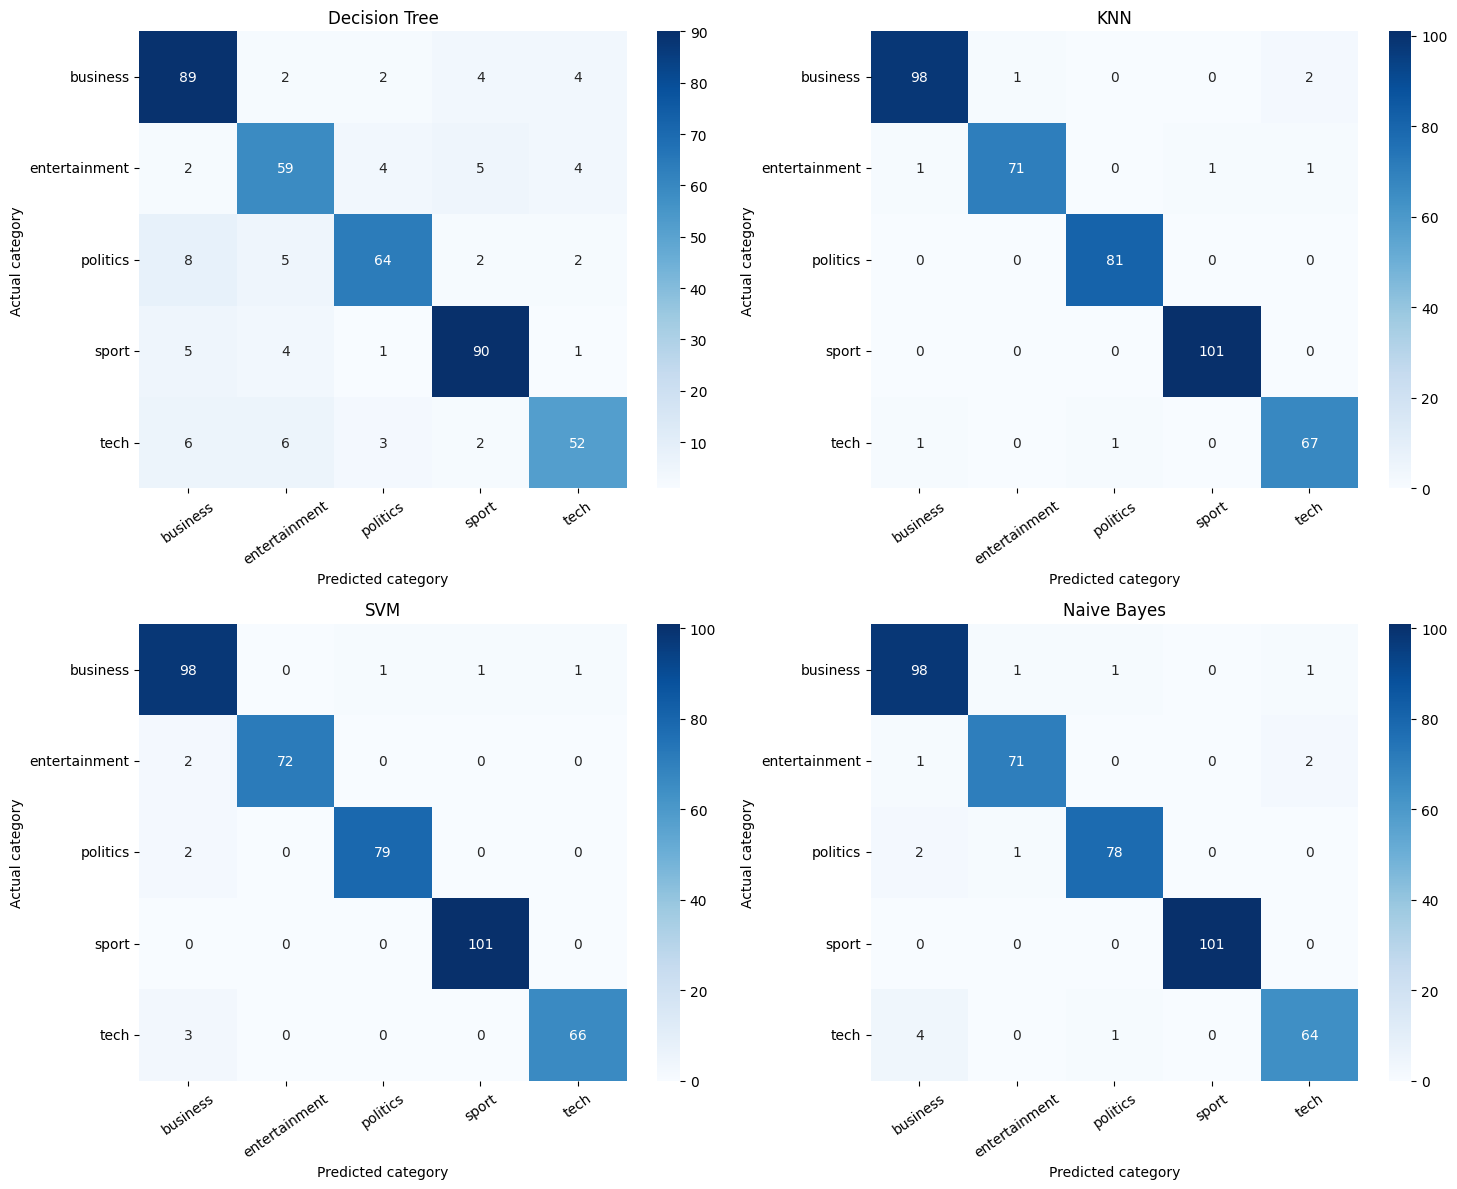

In [15]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(
    2, 2, figsize=(15, 12)
)

for ax, (name, y_pred) in zip(
    axes.flatten(), predictions.items()
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
best_model_name = comparison.loc[0, "Model"]
best_predictions = predictions[best_model_name]

print("Selected model:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        labels=class_names,
        zero_division=0
    )
)

best_cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_names
)

print("Confusion matrix:")
print(best_cm)

Selected model: KNN
               precision    recall  f1-score   support

     business       0.98      0.97      0.98       101
entertainment       0.99      0.96      0.97        74
     politics       0.99      1.00      0.99        81
        sport       0.99      1.00      1.00       101
         tech       0.96      0.97      0.96        69

     accuracy                           0.98       426
    macro avg       0.98      0.98      0.98       426
 weighted avg       0.98      0.98      0.98       426

Confusion matrix:
[[ 98   1   0   0   2]
 [  1  71   0   1   1]
 [  0   0  81   0   0]
 [  0   0   0 101   0]
 [  1   0   1   0  67]]


In [17]:
knn_results = []

for k in [3, 5, 7]:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    start = time.perf_counter()
    knn.fit(X_train_tfidf, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    pred = knn.predict(X_test_tfidf)
    test_time = time.perf_counter() - start

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            average="weighted", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, pred,
            average="weighted", zero_division=0
        ),
        "Training time (s)": train_time,
        "Testing time (s)": test_time
    })

knn_df = pd.DataFrame(knn_results)
display(knn_df.round(4))

,K,Accuracy,Precision,Recall,Weighted F1,Training time (s),Testing time (s)
0,3,0.9812,0.9814,0.9812,0.9812,0.0055,0.0788
1,5,0.9812,0.9813,0.9812,0.9812,0.0029,0.1124
2,7,0.9765,0.9767,0.9765,0.9764,0.0136,0.1296


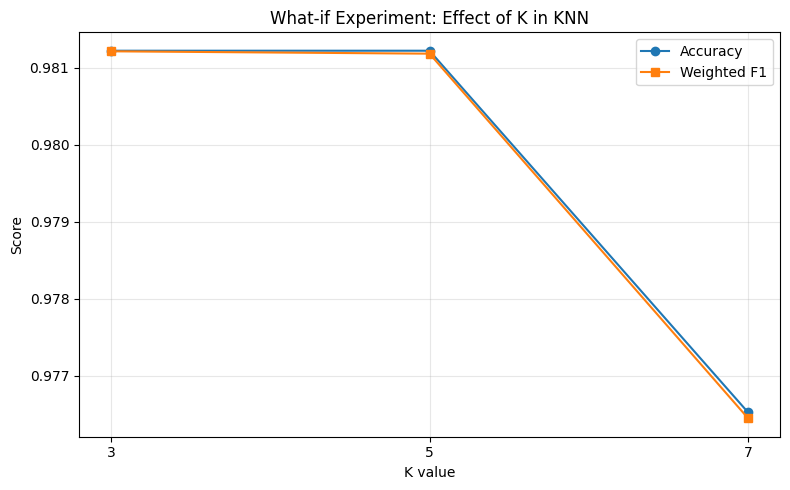

Best K by weighted F1: 3


In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_df["K"],
    knn_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_df["K"],
    knn_df["Weighted F1"],
    marker="s",
    label="Weighted F1"
)

plt.xticks([3, 5, 7])
plt.xlabel("K value")
plt.ylabel("Score")
plt.title("What-if Experiment: Effect of K in KNN")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_knn_row = knn_df.loc[knn_df["Weighted F1"].idxmax()]

print(
    "Best K by weighted F1:",
    int(best_knn_row["K"])
)

In [19]:
# Compare all four classifiers
comparison = results_df.sort_values(
    by="F1-score (weighted)",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL RANKING")
display(comparison.round(4))

best_model_name = comparison.loc[0, "Model"]

print("\nBest model:", best_model_name)
print(
    "Weighted F1-score:",
    round(comparison.loc[0, "F1-score (weighted)"], 4)
)
print(
    "Accuracy:",
    round(comparison.loc[0, "Accuracy"], 4)
)

FINAL MODEL RANKING


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),F1-score (macro),Training time (s),Testing time (s)
0,KNN,0.9812,0.9813,0.9812,0.9812,0.9801,0.0028,0.1324
1,SVM,0.9765,0.9771,0.9765,0.9766,0.9770,0.0974,0.0016
2,Naive Bayes,0.9671,0.9674,0.9671,0.9671,0.9655,0.0078,0.0010
3,Decision Tree,0.8310,0.8320,0.8310,0.8305,0.8253,0.9706,0.0014



Best model: KNN
Weighted F1-score: 0.9812
Accuracy: 0.9812


In [20]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Decision Tree
               precision    recall  f1-score   support

     business       0.81      0.88      0.84       101
entertainment       0.78      0.80      0.79        74
     politics       0.86      0.79      0.83        81
        sport       0.87      0.89      0.88       101
         tech       0.83      0.75      0.79        69

     accuracy                           0.83       426
    macro avg       0.83      0.82      0.83       426
 weighted avg       0.83      0.83      0.83       426


KNN
               precision    recall  f1-score   support

     business       0.98      0.97      0.98       101
entertainment       0.99      0.96      0.97        74
     politics       0.99      1.00      0.99        81
        sport       0.99      1.00      1.00       101
         tech       0.96      0.97      0.96        69

     accuracy                           0.98       426
    macro avg       0.98      0.98      0.98       426
 weighted avg       0.98      0.98      

In [21]:
results_df.to_csv(
    "classifier_comparison.csv",
    index=False
)

knn_df.to_csv(
    "knn_what_if_results.csv",
    index=False
)

print("Results files created successfully!")

Results files created successfully!


In [22]:
from google.colab import files

files.download("classifier_comparison.csv")
files.download("knn_what_if_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>